# 02 · The baseline: the simplest model that could work

Before building a neural network, we build the **simplest reasonable model** and measure it.
Its score is the bar our CNN has to beat. Without it, "our CNN gets 70%" means nothing.
With it, we can say *"the simple method gets X%, the CNN gets Y%, so the complexity was worth it."*

The recipe (all real code lives in `src/baseline.py`, this notebook just shows it):

1. **Squash** each 5 s clip into one list of **80 numbers** (a *feature vector*).
2. **Learn** from those 2000 rows with two classic models: Logistic Regression and Random Forest.
3. **Test fairly** with 5-fold cross-validation.

In [6]:
import sys; sys.path.insert(0, "..")          # so we can import our own src/ package
import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa.display
from matplotlib.colors import ListedColormap
from IPython.display import Audio, display
from sklearn.metrics import confusion_matrix
from src import audio
from src.baseline import load_features, mfcc_stats, cross_validate

BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})

def spec(ax, S, title, mel=True, **kw):
    librosa.display.specshow(S, sr=audio.SAMPLE_RATE, hop_length=audio.HOP_LENGTH, x_axis="time",
                             y_axis="mel" if mel else None, ax=ax, cmap="magma", **kw)
    ax.set_title(title, loc="left")

def crop_f0(ax, f0):
    """Feature 0 (loudness) is ~10x bigger than the rest; crop the axis so the others are visible."""
    ax.set_ylim(-60, 100)
    ax.annotate(f"f0 = {f0:.0f} (off the chart)", (0, -60), (2, -45), color=MUTED, fontsize=9)

X, y, fold, meta = load_features()             # the 80 numbers for all 2000 clips (cached)
names = meta.drop_duplicates("target").sort_values("target")["category"].tolist()
print("X:", X.shape, "  -> 2000 clips, 80 numbers each")

X: (2000, 80)   -> 2000 clips, 80 numbers each


## Step 1 · One clip → 80 numbers

Classic models like Random Forest can't take a picture as input. They need **one fixed-length list of
numbers per clip**. Watch one dog clip get squashed:

- **①** the log-mel spectrogram you know: 64 rows × 500 columns = 32,000 numbers.
- **②** **MFCC**: each column squeezed from 64 numbers to 20 that describe its *overall shape*
  (is the energy low or high? smooth fog or sharp peaks?). Row 0 is roughly overall loudness.
- **③** summarise each MFCC row over time: its **mean** (average level) and **std** (how much it varies),
  and the same for the **Δ** (how fast it changes frame to frame). 20 × 4 = **80 numbers**.

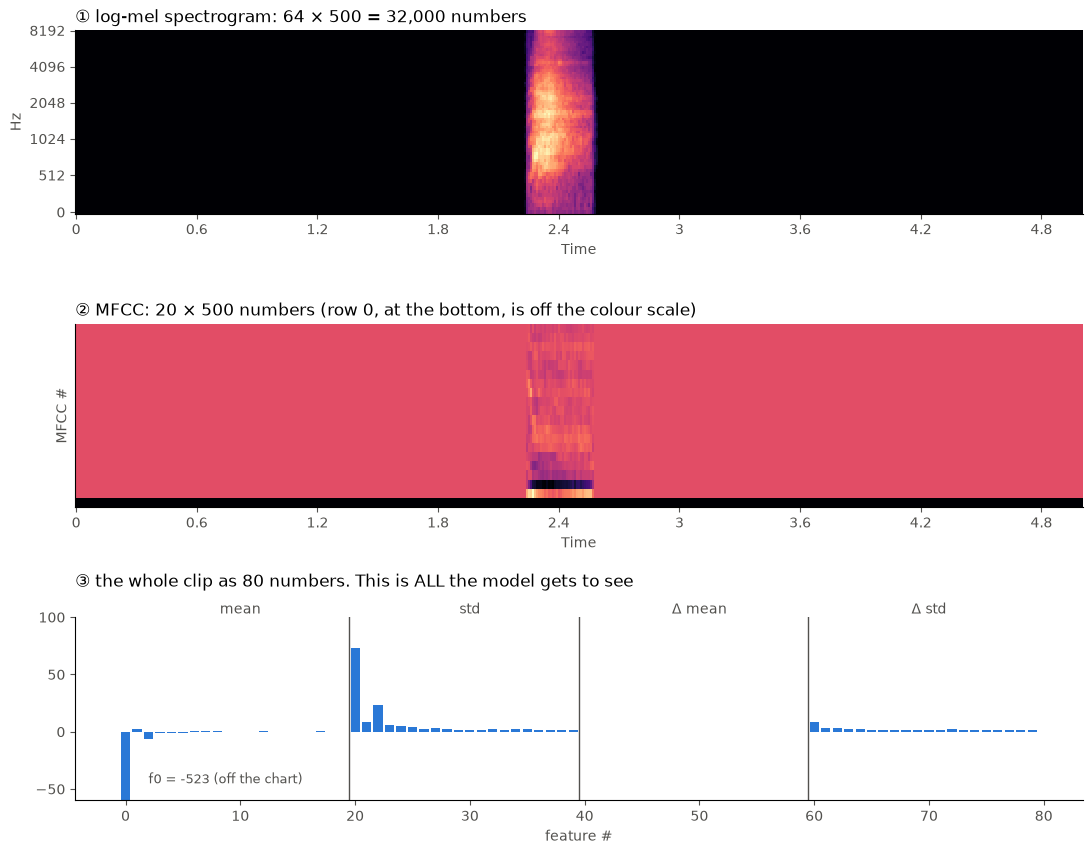

In [7]:
clip = meta[meta.category == "dog"].iloc[0]
wave = audio.load(clip.path)
m = audio.mfcc(wave)
feat = mfcc_stats(m)

fig, axes = plt.subplots(3, 1, figsize=(13, 10), gridspec_kw={"hspace": 0.6})
spec(axes[0], audio.log_mel(wave), "① log-mel spectrogram: 64 × 500 = 32,000 numbers")
lo, hi = m[1:].min(), m[1:].max()              # colour scale from rows 1-19; row 0 is far bigger
spec(axes[1], m, "② MFCC: 20 × 500 numbers (row 0, at the bottom, is off the colour scale)", mel=False, vmin=lo, vmax=hi)
axes[1].set_ylabel("MFCC #")
axes[2].bar(range(80), feat, color=BLUE)
for x in (20, 40, 60): axes[2].axvline(x - 0.5, color=MUTED, lw=1)
for x, lab in zip((10, 30, 50, 70), ("mean", "std", "Δ mean", "Δ std")):
    axes[2].text(x, 1.02, lab, transform=axes[2].get_xaxis_transform(), ha="center", color=MUTED)
axes[2].set_title("③ the whole clip as 80 numbers. This is ALL the model gets to see", loc="left", pad=22)
axes[2].set_xlabel("feature #"); crop_f0(axes[2], feat[0])
plt.show()
display(Audio(wave, rate=audio.SAMPLE_RATE))

Notice feature 0 is so big it doesn't fit on the chart (about −500, vs. roughly ±50 for the others):
MFCC 0 (loudness) lives on a much bigger scale. Most other bars are small because this clip is mostly silence.
That's why the Logistic Regression pipeline starts with a `StandardScaler`, which rescales every
feature to a similar range so the big one doesn't drown out the others.

Do this for all 2000 clips and you get a plain **table**: one row per clip, 80 feature columns, and the answer.

In [8]:
table = pd.DataFrame(X.round(1), columns=[f"f{i}" for i in range(80)])
table.insert(0, "category", meta.category); table.insert(1, "fold", meta.fold)
table.head(8)

,category,fold,f0,f1,f2,f3,f4,f5,f6,f7,...,f70,f71,f72,f73,f74,f75,f76,f77,f78,f79
0,dog,1,-522.799988,2.000000,-6.200000,-1.5,-1.0,-0.8,0.3,0.700000,...,1.7,1.4,2.5,1.9,1.7,1.5,1.8,1.3,1.3,1.4
1,chirping_birds,1,-240.399994,-12.800000,-24.000000,-5.7,-32.0,-19.1,-9.6,-18.799999,...,6.4,6.4,5.8,5.2,5.4,5.6,6.0,5.8,5.8,5.8
2,vacuum_cleaner,1,-94.199997,30.100000,-0.100000,4.9,-6.2,13.3,-3.5,12.600000,...,5.9,5.7,5.8,5.4,5.2,5.3,5.5,5.2,5.5,5.6
3,vacuum_cleaner,1,-93.500000,29.700001,-0.100000,4.8,-4.8,12.4,-3.9,10.000000,...,5.6,5.5,5.4,5.6,5.5,5.5,5.3,5.1,5.0,5.2
4,thunderstorm,1,-400.899994,84.699997,33.099998,18.4,2.2,1.0,-4.6,7.200000,...,5.7,5.5,5.7,6.1,5.7,5.2,5.4,5.7,5.2,5.1
5,thunderstorm,1,-382.799988,95.800003,29.400000,9.7,-2.0,2.7,-3.9,7.700000,...,6.0,5.5,5.4,5.4,5.4,5.3,5.5,5.5,5.1,5.2
6,door_wood_knock,1,-410.399994,66.500000,14.700000,13.7,2.1,-1.2,6.2,3.900000,...,4.2,4.1,4.7,4.4,4.1,3.9,3.9,3.5,3.9,4.0
7,can_opening,1,-462.799988,5.300000,7.900000,9.5,2.9,13.4,12.1,2.100000,...,5.5,5.3,5.2,5.1,5.0,5.2,5.3,4.7,4.6,4.6


### What the squashing throws away

Averaging over time forgets **when** things happened. To prove it, take a clock-tick clip and **shuffle
its time columns randomly**. The picture becomes nonsense, but the *mean* and *std* of every MFCC stay
exactly the same, because an average doesn't care about order.

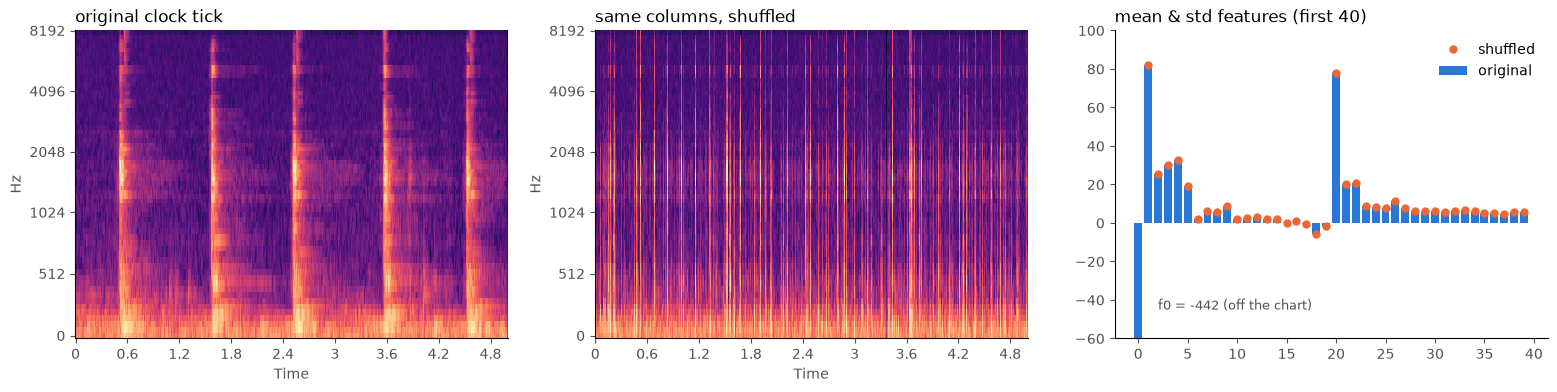

40 of 80 features are identical after shuffling time.
Only the Δ features notice anything, and they only see 'changes fast', not the rhythm.


In [9]:
clip = meta[meta.category == "clock_tick"].iloc[0]
wave = audio.load(clip.path)
m = audio.mfcc(wave)
perm = np.random.default_rng(0).permutation(m.shape[1])       # a random new order for the 500 columns
f_orig, f_shuf = mfcc_stats(m), mfcc_stats(m[:, perm])

fig, axes = plt.subplots(1, 3, figsize=(19, 4))
spec(axes[0], audio.log_mel(wave), "original clock tick")
spec(axes[1], audio.log_mel(wave)[:, perm], "same columns, shuffled")
axes[2].bar(range(40), f_orig[:40], color=BLUE, label="original")
axes[2].plot(range(40), f_shuf[:40], "o", color=ORANGE, ms=5, label="shuffled")
axes[2].set_title("mean & std features (first 40)", loc="left"); axes[2].legend(frameon=False)
crop_f0(axes[2], f_orig[0])
plt.show()
same = np.isclose(f_orig, f_shuf).sum()
print(f"{same} of 80 features are identical after shuffling time.")
print("Only the Δ features notice anything, and they only see 'changes fast', not the rhythm.")

Keep this in mind: **it's the baseline's built-in weakness**, and it's exactly what the CNN will fix.

## Step 2 · Two classic models

| Model | How it decides |
|---|---|
| **Logistic Regression** | learns a weight for each of the 80 numbers, per class. Weighted sum → score per class → highest wins. A "straight-line" (linear) model. |
| **Random Forest** | 500 **decision trees**, each asking yes/no questions (*"is f3 above −12? is f41 below 0.5?"*) down to a guess. All trees vote. Can learn more complex rules. |

## Step 3 · Test fairly: 5-fold cross-validation

Testing on clips the model trained on measures *memory*, not skill. ESC-50 comes in 5 folds of 400 clips,
so we run **5 rounds**. Each round, one fold is hidden during training and used as the test:

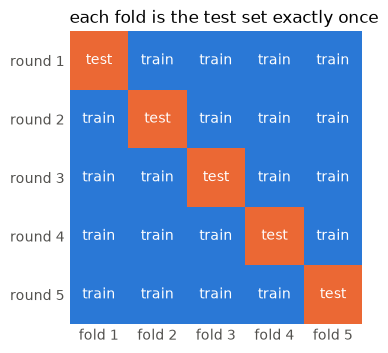

In [10]:
grid = np.array([[int(f == r) for f in range(1, 6)] for r in range(1, 6)])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.imshow(grid, cmap=ListedColormap([BLUE, ORANGE]))
for r in range(5):
    for f in range(5):
        ax.text(f, r, "test" if grid[r, f] else "train", ha="center", va="center", color="white")
ax.set_xticks(range(5), [f"fold {f}" for f in range(1, 6)]); ax.set_yticks(range(5), [f"round {r}" for r in range(1, 6)])
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("each fold is the test set exactly once", loc="left")
plt.show()

Now run it for real. For each model: 5 rounds of *train on 1600 clips → predict the 400 hidden ones*.
**Accuracy** = fraction of hidden clips where the guess was right. With 50 classes, random guessing gets **2%**.

logistic_regression  mean accuracy 0.478   per round: [0.478 0.45  0.488 0.528 0.448]
random_forest        mean accuracy 0.541   per round: [0.512 0.542 0.562 0.518 0.57 ]


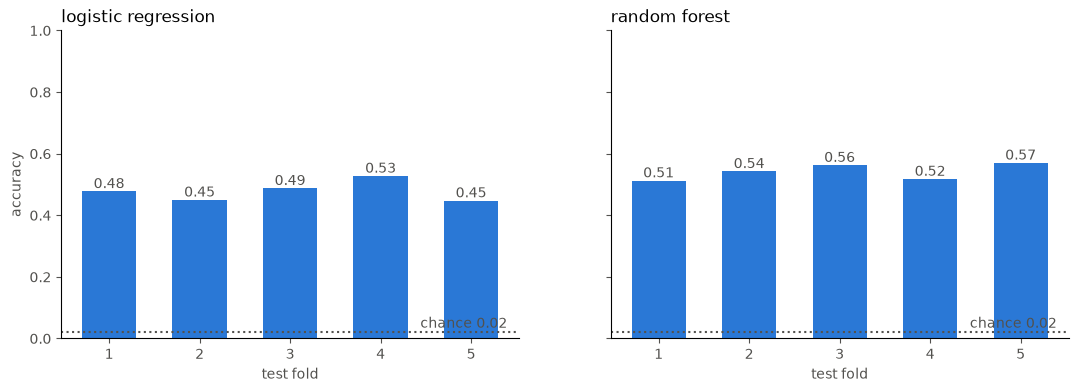

In [11]:
results = {}
for name in ["logistic_regression", "random_forest"]:
    accs, y_pred = cross_validate(name, X, y, fold)
    results[name] = y_pred
    print(f"{name:20s} mean accuracy {np.mean(accs):.3f}   per round: {np.round(accs, 3)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, results):
    accs = [np.mean(results[name][fold == k] == y[fold == k]) for k in range(1, 6)]
    bars = ax.bar(range(1, 6), accs, color=BLUE, width=0.6)
    ax.bar_label(bars, fmt="%.2f", color=MUTED)
    ax.axhline(0.02, color=MUTED, ls=":"); ax.text(5.4, 0.035, "chance 0.02", color=MUTED, ha="right")
    ax.set_title(name.replace("_", " "), loc="left"); ax.set_xlabel("test fold"); ax.set_ylim(0, 1)
axes[0].set_ylabel("accuracy")
plt.show()

The 5 bars are close to each other. That's the point of cross-validation: the score isn't one lucky split.

## Where does it go wrong? The confusion matrix

From here on we look at the better model, **Random Forest**.
Each **row** is the *true* class, each **column** is what the model *guessed*, and the colour is the
fraction of that row's clips. A dark **diagonal** means right answers; a dark square **off** the diagonal
means a mix-up.

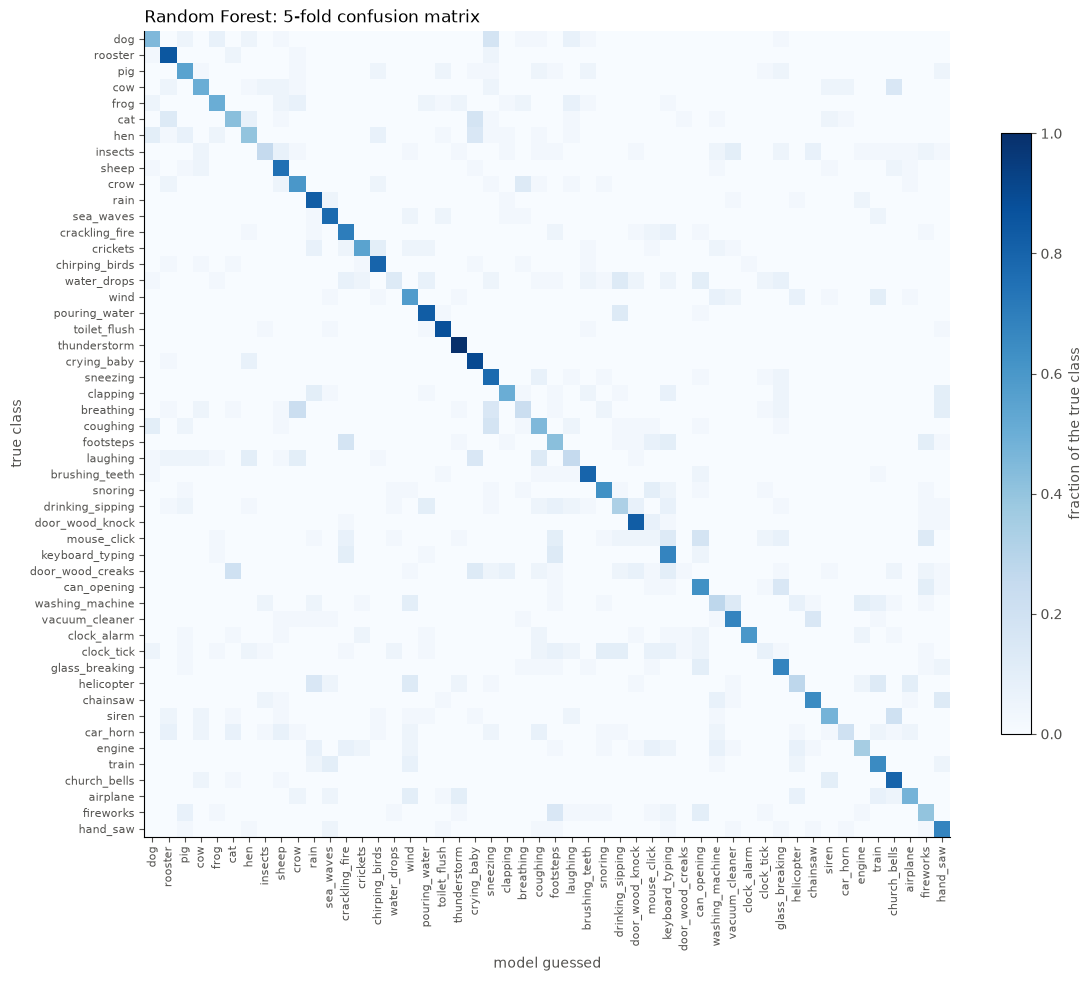

In [12]:
y_pred = results["random_forest"]
cm = confusion_matrix(y, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(13, 13))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(50), names, rotation=90, fontsize=8); ax.set_yticks(range(50), names, fontsize=8)
ax.set_xlabel("model guessed"); ax.set_ylabel("true class")
fig.colorbar(im, ax=ax, shrink=0.6, label="fraction of the true class")
ax.set_title("Random Forest: 5-fold confusion matrix", loc="left")
plt.show()

The same diagonal, as a sorted bar chart, to see which classes are easy and which are hard:

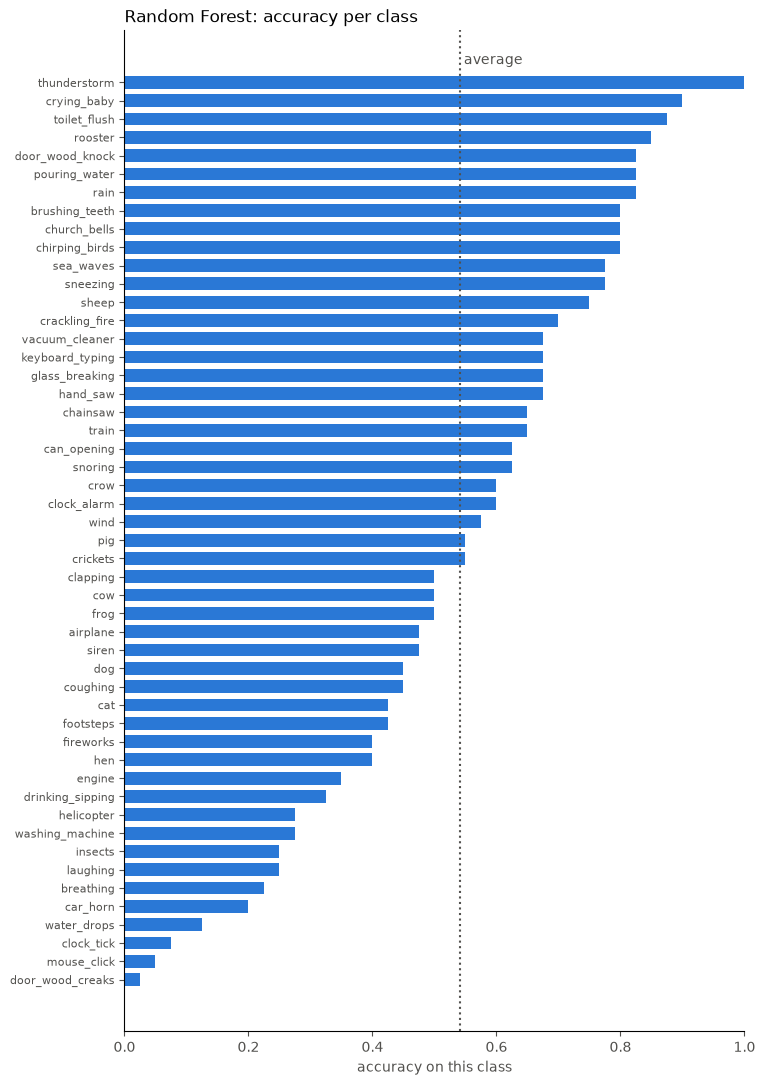

In [13]:
per_class = pd.Series(np.diag(cm), index=names).sort_values()
fig, ax = plt.subplots(figsize=(8, 13))
ax.barh(per_class.index, per_class.values, color=BLUE, height=0.7)
ax.axvline(per_class.mean(), color=MUTED, ls=":"); ax.text(per_class.mean(), 50, " average", color=MUTED)
ax.set_xlim(0, 1); ax.set_xlabel("accuracy on this class"); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Random Forest: accuracy per class", loc="left")
plt.show()

**Look at the top and the bottom of that chart with Notebook 01's shapes in mind.**
Near the top are mostly steady, fog-like or long harmonic sounds (thunderstorm, rain, crying baby,
rooster): their 5 s *average* is a good fingerprint. Near the bottom are mostly short clicks and one-off
events (clock tick, mouse click, water drops): a single tick averaged with seconds of silence leaves
almost nothing.

It's not a perfect rule. `door_wood_knock` is also a click sound, yet it scores high. Plot a few knock
clips and try to work out why its *average* is still distinctive.

## The most common mix-ups

In [14]:
pairs = pd.DataFrame({"true": np.array(names)[y], "guessed": np.array(names)[y_pred]})
mixups = pairs[pairs.true != pairs.guessed].value_counts().head(10)
mixups.rename("clips (of 40)").to_frame()

,,clips (of 40)
true,guessed,
breathing,crow,9
door_wood_creaks,cat,8
siren,church_bells,8
dog,sneezing,7
footsteps,crackling_fire,7
mouse_click,can_opening,7
cat,crying_baby,7
coughing,sneezing,7
fireworks,footsteps,6


### Look at the #1 mix-up yourself

Left: a clip the model got **wrong**. Right: a clip of the class it **guessed**, which the model got right.
Listen to both. Do they really sound alike, or do they only have similar *averages*?

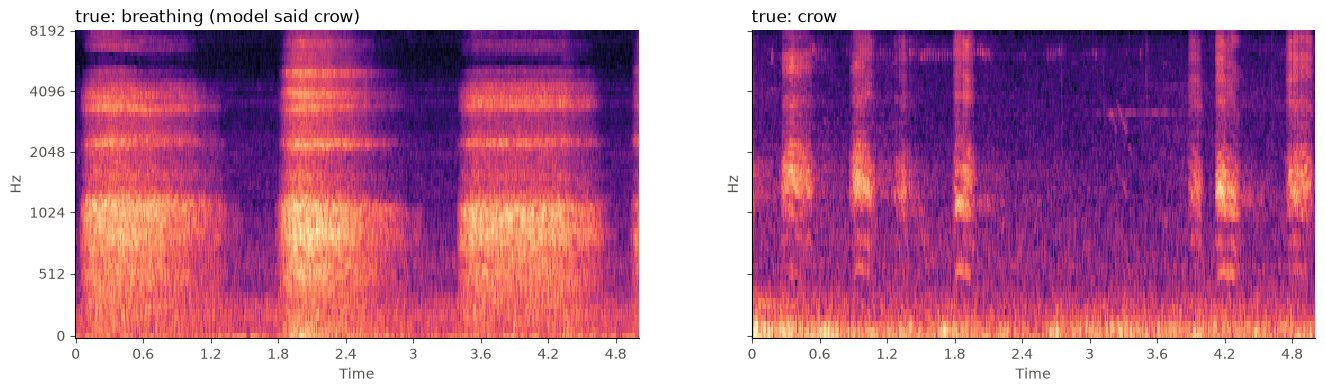

In [15]:
TRUE, GUESS = mixups.index[0]          # change to mixups.index[1], [2] ... to see others
wrong = meta[(meta.category == TRUE) & (y_pred == names.index(GUESS))].iloc[0]
right = meta[(meta.category == GUESS) & (y_pred == y)].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, row, label in [(axes[0], wrong, f"true: {TRUE} (model said {GUESS})"), (axes[1], right, f"true: {GUESS}")]:
    w = audio.load(row.path)
    spec(ax, audio.log_mel(w), label)
    display(Audio(w, rate=audio.SAMPLE_RATE))
plt.show()

## Takeaway

- The baseline turns each clip into 80 averaged numbers and does **far better than chance**. Plain
  statistics already capture a lot about *texture* (rain vs. rooster).
- It **fails on short events and rhythm** (ticks, knocks, clicks), because averaging over time erases
  *when* things happen. We proved that with the shuffle test.
- **That's the case for the CNN (Day 2):** it looks at the spectrogram as a picture and learns shapes
  wherever they occur in time, not just averages.

**Your turn:** pick one class near the top and one near the bottom of the per-class chart, plot their
spectrograms (Notebook 01 has the code), and explain the difference using the four shapes.